# Bank Customer Churn Prediction

**Portfolio project | Supervised learning | Customer retention**

This notebook turns a classroom archive into a reproducible analysis that can be explained in an interview. It uses a public, anonymized bank-customer dataset and keeps the business question simple: **which customers are more likely to churn, and how accurately can we prioritize them for retention outreach?**

## tl;dr

- The dataset contains **10,000 customers** and the observed churn rate is **20.37%**.
- A tuned random forest is evaluated on an untouched test set using ROC-AUC, precision, recall, and F1—not accuracy alone.
- On the untouched test set, the tuned random forest achieves **ROC-AUC 0.862**, with **53.2% precision** and **73.2% recall** at the default threshold.
- A validation-selected threshold of about **0.55** raises test precision to **57.7%** while lowering recall to **66.3%**, making the operating trade-off explicit.
- Findings are associative, not causal; this public dataset has no timestamps, campaign costs, or intervention outcomes.

## Context & Methods

### Business question

A bank cannot contact every customer with the same retention offer. A churn model can rank customers by estimated risk so a retention team can focus on a smaller group. The model is useful only if its evaluation reflects that decision.

### Key assumptions

- `Exited = 1` means the customer churned; one row represents one customer.
- The dataset is a static public sample, not a live production extract. Its observation date and collection process are not available.
- Customer attributes are assumed to be available before the churn outcome. The file does not include timestamps, so this cannot be independently verified.
- Segment differences and model importance are **associations**, not proof that a feature causes churn.

### Evaluation design

1. Keep 20% of the data as an untouched final test set.
2. Split the remaining data into model-training and threshold-validation sets.
3. Fit encoders and scalers inside a pipeline to prevent test-data leakage.
4. Compare a naive baseline, logistic regression, KNN, and random forest.
5. Tune the random forest with five-fold cross-validation using ROC-AUC.
6. Select an alternative probability threshold on validation data, then evaluate once on the test set.

### 1. Setup

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
DATA_PATH = Path("bank.data.csv")

BLUE = "#2F5D8A"
GOLD = "#C8922E"
ORANGE = "#D9773D"
INK = "#263238"
GREY = "#8C98A4"
LIGHT = "#E8EDF2"

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "axes.edgecolor": GREY,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
})

## Data

### 2. Load and inspect the source

Source: [Predicting Churn for Bank Customers](https://www.kaggle.com/adammaus/predicting-churn-for-bank-customers), as referenced by the original course notebook.

The identifiers (`RowNumber`, `CustomerId`, and `Surname`) are useful for quality checks but are excluded from modeling because they should not represent customer behavior.

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Expected {DATA_PATH.resolve()}. Put bank.data.csv in the same folder as this notebook."
    )

customers = pd.read_csv(DATA_PATH)
print(f"Rows: {customers.shape[0]:,} | Columns: {customers.shape[1]}")
customers.head()

### 3. Validate the dataset

In [3]:
expected_columns = {
    "RowNumber", "CustomerId", "Surname", "CreditScore", "Geography",
    "Gender", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard",
    "IsActiveMember", "EstimatedSalary", "Exited",
}

quality_checks = pd.DataFrame({
    "check": [
        "Expected schema",
        "Exact duplicate rows",
        "Duplicate customer IDs",
        "Missing values",
        "Binary target",
    ],
    "result": [
        set(customers.columns) == expected_columns,
        customers.duplicated().sum() == 0,
        customers["CustomerId"].duplicated().sum() == 0,
        customers.isna().sum().sum() == 0,
        set(customers["Exited"].unique()) == {0, 1},
    ],
    "observed": [
        f"{customers.shape[1]} columns",
        int(customers.duplicated().sum()),
        int(customers["CustomerId"].duplicated().sum()),
        int(customers.isna().sum().sum()),
        sorted(customers["Exited"].unique().tolist()),
    ],
})

assert quality_checks["result"].all(), "A required data-quality check failed."
quality_checks

,check,result,observed
0,Expected schema,True,14 columns
1,Exact duplicate rows,True,0
2,Duplicate customer IDs,True,0
3,Missing values,True,0
4,Binary target,True,"[0, 1]"


In [4]:
numeric_ranges = customers[
    ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
].agg(["min", "median", "max"]).T
numeric_ranges

,min,median,max
CreditScore,350.00,652.000,850.00
Age,18.00,37.000,92.00
Tenure,0.00,5.000,10.00
Balance,0.00,97198.540,250898.09
NumOfProducts,1.00,1.000,4.00
EstimatedSalary,11.58,100193.915,199992.48


**Data-quality interpretation.** The file is structurally clean for a classroom model: no nulls, no duplicate rows, and no duplicate customer IDs. However, it has no timestamp or data dictionary, so freshness and the exact timing of features relative to churn cannot be verified. That limitation matters more than the absence of nulls.

### 4. Examine class balance

In [5]:
class_summary = (
    customers["Exited"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Stayed", 1: "Churned"})
    .to_frame("customers")
)
class_summary["share"] = class_summary["customers"] / len(customers)
class_summary

,customers,share
Exited,,
Stayed,7963,0.7963
Churned,2037,0.2037


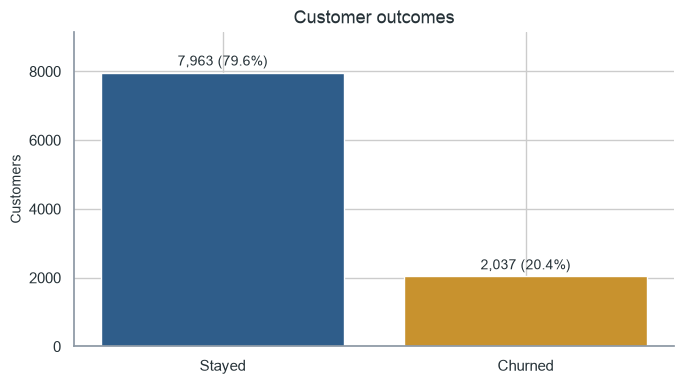

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_summary.index, class_summary["customers"], color=[BLUE, GOLD])
ax.set_title("Customer outcomes")
ax.set_ylabel("Customers")
ax.set_xlabel("")
ax.set_ylim(0, class_summary["customers"].max() * 1.15)
for bar, count, share in zip(bars, class_summary["customers"], class_summary["share"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 120,
        f"{count:,} ({share:.1%})",
        ha="center",
        va="bottom",
        fontsize=10,
    )
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

A model that predicts “Stayed” for everyone already achieves 79.63% accuracy. This is why the rest of the notebook emphasizes ROC-AUC, recall, precision, and F1.

### 5. Explore churn rates by customer segment

In [7]:
def segment_churn_rate(frame, column):
    return (
        frame.groupby(column, observed=False)["Exited"]
        .agg(customers="size", churn_rate="mean")
        .reset_index()
        .sort_values("churn_rate")
    )

segments = {
    "Geography": segment_churn_rate(customers, "Geography"),
    "Gender": segment_churn_rate(customers, "Gender"),
    "Active membership": segment_churn_rate(customers, "IsActiveMember").assign(
        IsActiveMember=lambda x: x["IsActiveMember"].map({0: "Inactive", 1: "Active"})
    ),
    "Number of products": segment_churn_rate(customers, "NumOfProducts"),
}

display(segments["Geography"])
display(segments["Gender"])
display(segments["Active membership"])
display(segments["Number of products"])

,Geography,customers,churn_rate
0,France,5014,0.161548
2,Spain,2477,0.166734
1,Germany,2509,0.324432


,Gender,customers,churn_rate
1,Male,5457,0.164559
0,Female,4543,0.250715


,IsActiveMember,customers,churn_rate
1,Active,5151,0.142691
0,Inactive,4849,0.268509


,NumOfProducts,customers,churn_rate
1,2,4590,0.075817
0,1,5084,0.277144
2,3,266,0.827068
3,4,60,1.000000


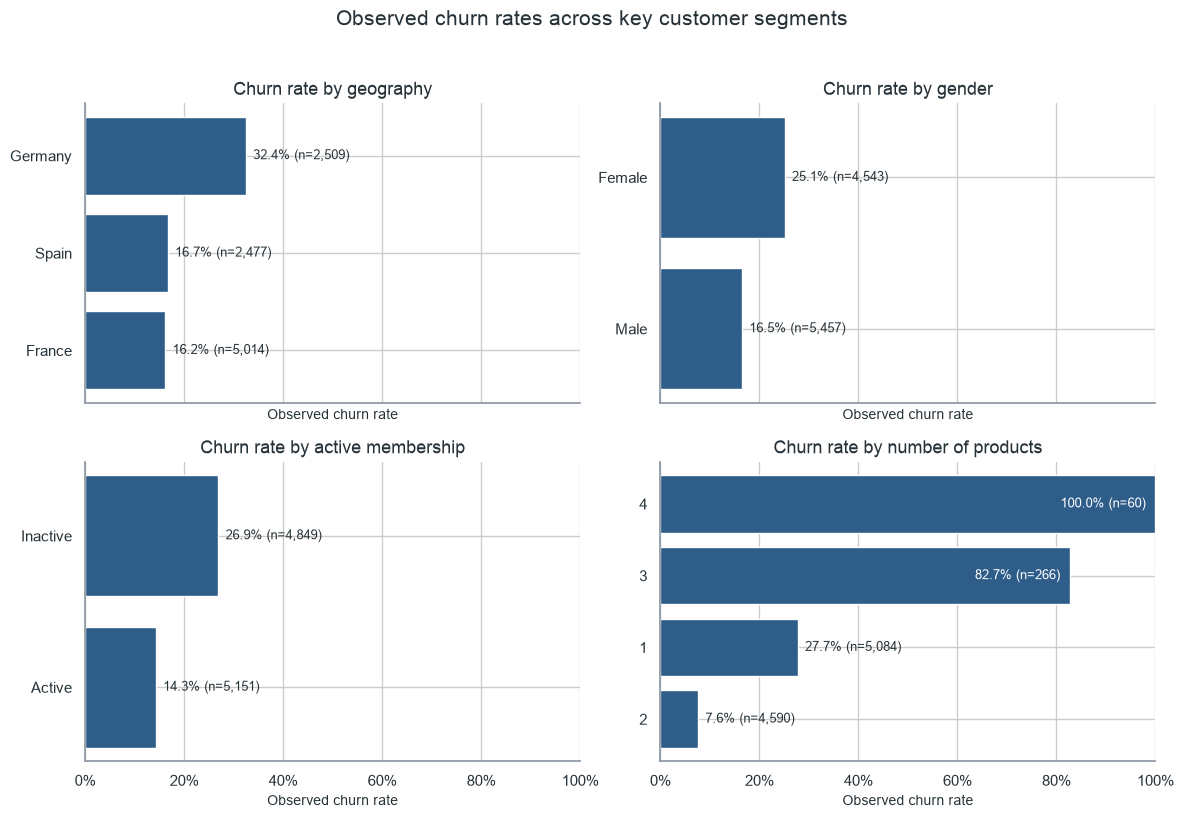

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
chart_specs = [
    (axes[0, 0], segments["Geography"], "Geography", "Geography"),
    (axes[0, 1], segments["Gender"], "Gender", "Gender"),
    (axes[1, 0], segments["Active membership"], "IsActiveMember", "Active membership"),
    (axes[1, 1], segments["Number of products"], "NumOfProducts", "Number of products"),
]

for ax, data, label_col, title in chart_specs:
    labels = data[label_col].astype(str)
    bars = ax.barh(labels, data["churn_rate"], color=BLUE)
    ax.set_title(f"Churn rate by {title.lower()}")
    ax.set_xlim(0, 1.0)
    ax.set_xlabel("Observed churn rate")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    for bar, rate, count in zip(bars, data["churn_rate"], data["customers"]):
        if rate >= 0.75:
            label_x, label_align, label_color = rate - 0.02, "right", "white"
        else:
            label_x, label_align, label_color = rate + 0.015, "left", INK
        ax.text(
            label_x,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.1%} (n={count:,})",
            va="center",
            ha=label_align,
            color=label_color,
            fontsize=9,
        )
    sns.despine(ax=ax)

fig.suptitle("Observed churn rates across key customer segments", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

**Reasonableness check.** Customers with four products show 100% churn, but that group contains only 60 observations. The rate is real within this file, yet too small and unusual to generalize without more data. The charts therefore show both the rate and the sample size.

## Results

### 6. Create leakage-safe train, validation, and test sets

The test set stays untouched until the model and probability threshold are finalized. Stratification preserves the churn share across all splits.

In [9]:
target = customers["Exited"]
features = customers.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])

X_development, X_test, y_development, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    stratify=target,
    random_state=RANDOM_STATE,
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    stratify=y_development,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_validation), len(X_test)],
    "churn_rate": [y_train.mean(), y_validation.mean(), y_test.mean()],
}, index=["Train", "Validation", "Test"])
split_summary

,rows,churn_rate
Train,6000,0.203833
Validation,2000,0.203500
Test,2000,0.203500


### 7. Build the preprocessing and modeling pipeline

In [10]:
categorical_features = ["Geography", "Gender"]
numeric_features = [column for column in features.columns if column not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", StandardScaler(), numeric_features),
    ]
)

def make_pipeline(model):
    return Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", model),
    ])

def evaluate_probabilities(model_name, y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions).ravel()
    return {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    }

### 8. Compare baseline models on validation data

In [11]:
candidate_models = {
    "Naive baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=9),
    "Random forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

validation_rows = []
fitted_candidates = {}
for model_name, model in candidate_models.items():
    pipeline = make_pipeline(model)
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_validation)[:, 1]
    validation_rows.append(
        evaluate_probabilities(model_name, y_validation, probabilities)
    )
    fitted_candidates[model_name] = pipeline

validation_results = (
    pd.DataFrame(validation_rows)
    .set_index("model")
    .sort_values("roc_auc", ascending=False)
)
validation_results[["accuracy", "precision", "recall", "f1", "roc_auc"]].round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Random forest,0.858,0.789,0.413,0.542,0.855
KNN,0.837,0.714,0.332,0.453,0.810
Logistic regression,0.809,0.584,0.214,0.313,0.757
Naive baseline,0.796,0.000,0.000,0.000,0.500


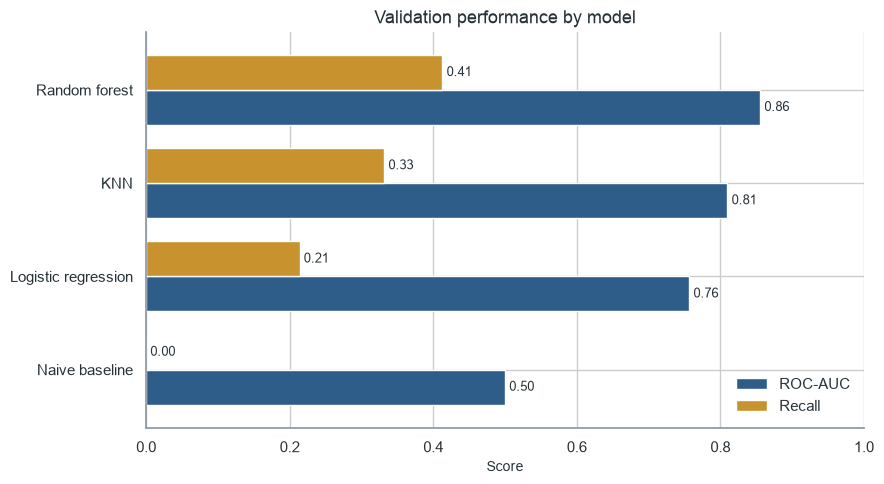

In [12]:
plot_data = (
    validation_results[["roc_auc", "recall"]]
    .rename(columns={"roc_auc": "ROC-AUC", "recall": "Recall"})
    .sort_values("ROC-AUC")
)
ax = plot_data.plot.barh(color=[BLUE, GOLD], figsize=(9, 5), width=0.75)
ax.set_title("Validation performance by model")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 1.0)
ax.legend(loc="lower right", frameon=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 9. Tune the random forest

The original archive tuned models using accuracy. Here, five-fold cross-validation optimizes ROC-AUC because it evaluates how well the model ranks churners above non-churners across all possible thresholds.

In [13]:
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

random_forest_pipeline = make_pipeline(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
)

parameter_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [6, 10, None],
    "model__min_samples_leaf": [1, 5],
    "model__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    random_forest_pipeline,
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=cross_validation,
    n_jobs=-1,
    refit=True,
)
grid_search.fit(X_train, y_train)

print(f"Best cross-validated ROC-AUC: {grid_search.best_score_:.3f}")
print("Best parameters:")
for name, value in grid_search.best_params_.items():
    print(f"  {name.replace('model__', '')}: {value}")

Best cross-validated ROC-AUC: 0.856
Best parameters:
  class_weight: balanced
  max_depth: 10
  min_samples_leaf: 5
  n_estimators: 400


### 10. Select a threshold on validation data

The default 0.50 threshold is not a law. A retention team may accept more false positives if contacting a customer is inexpensive compared with losing one. This notebook selects the validation threshold that maximizes F1, balancing precision and recall. A real bank should instead use an explicit cost-benefit function.

In [14]:
tuned_validation_probabilities = grid_search.best_estimator_.predict_proba(X_validation)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(
    y_validation,
    tuned_validation_probabilities,
)
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / np.maximum(precision_values[:-1] + recall_values[:-1], 1e-12)
)
best_threshold_index = int(np.nanargmax(f1_values))
selected_threshold = float(thresholds[best_threshold_index])

threshold_summary = pd.DataFrame({
    "selected_threshold": [selected_threshold],
    "validation_precision": [precision_values[best_threshold_index]],
    "validation_recall": [recall_values[best_threshold_index]],
    "validation_f1": [f1_values[best_threshold_index]],
})
threshold_summary.round(3)

,selected_threshold,validation_precision,validation_recall,validation_f1
0,0.551,0.611,0.668,0.638


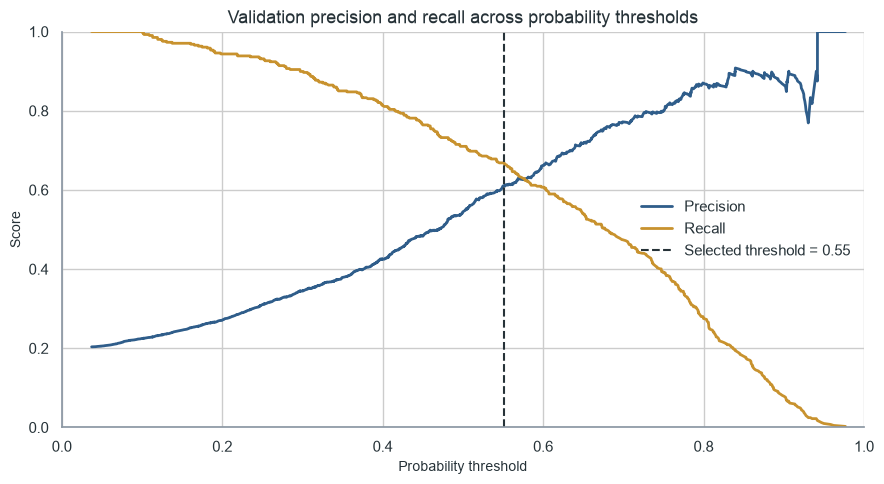

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, precision_values[:-1], color=BLUE, label="Precision", linewidth=2)
ax.plot(thresholds, recall_values[:-1], color=GOLD, label="Recall", linewidth=2)
ax.axvline(selected_threshold, color=INK, linestyle="--", linewidth=1.5,
           label=f"Selected threshold = {selected_threshold:.2f}")
ax.set_title("Validation precision and recall across probability thresholds")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="center right")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 11. Evaluate once on the untouched test set

In [16]:
final_model = clone(grid_search.best_estimator_)
final_model.fit(X_development, y_development)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame([
    evaluate_probabilities("Tuned RF — default threshold", y_test, test_probabilities, 0.50),
    evaluate_probabilities("Tuned RF — selected threshold", y_test, test_probabilities, selected_threshold),
]).set_index("model")

test_results[
    ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc",
     "false_positives", "false_negatives", "true_positives"]
].round(3)

,threshold,accuracy,precision,recall,f1,roc_auc,false_positives,false_negatives,true_positives
model,,,,,,,,,
Tuned RF — default threshold,0.500,0.814,0.532,0.732,0.616,0.862,262,109,298
Tuned RF — selected threshold,0.551,0.832,0.577,0.663,0.617,0.862,198,137,270


**How to read the result.** ROC-AUC stays the same because changing the threshold does not change the ranking. In this run, the validation-selected threshold is higher than 0.50, so it raises precision and reduces false-positive outreach while lowering recall. A lower threshold would move the trade-off in the opposite direction. The preferred operating point depends on retention economics.

### 12. Inspect feature importance

Permutation importance measures how much test ROC-AUC falls when one original feature is shuffled. It is evaluated on held-out data and avoids the original notebook's duplicated salary conversion. Importance still does not imply causation.

In [17]:
importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
feature_importance = (
    pd.DataFrame({
        "feature": X_test.columns,
        "importance_mean": importance.importances_mean,
        "importance_std": importance.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
feature_importance.round(4)

,feature,importance_mean,importance_std
0,Age,0.1251,0.0055
1,NumOfProducts,0.1030,0.0094
2,Balance,0.0304,0.0043
3,IsActiveMember,0.0291,0.0032
4,Geography,0.0224,0.0020
5,Gender,0.0090,0.0023
6,EstimatedSalary,0.0001,0.0015
7,CreditScore,-0.0001,0.0008
8,HasCrCard,-0.0004,0.0005
9,Tenure,-0.0011,0.0007


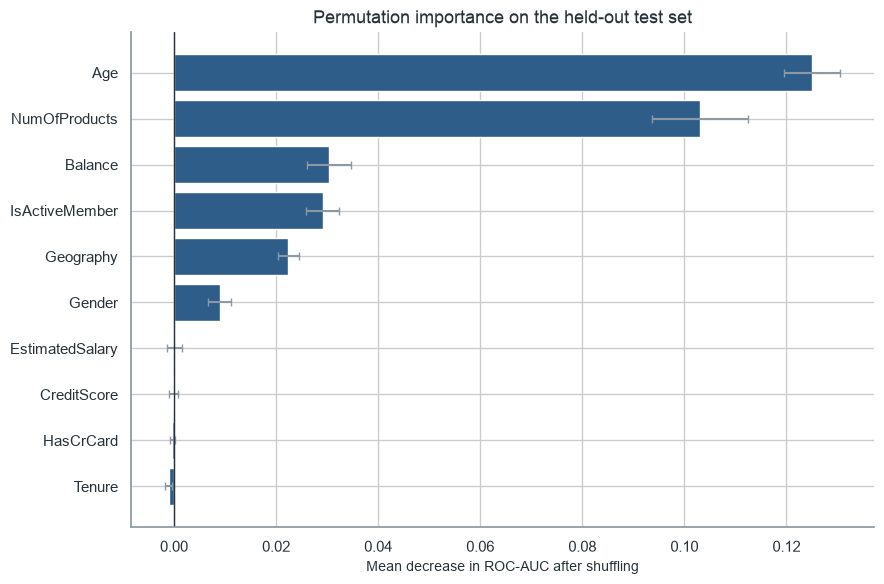

In [18]:
plot_importance = feature_importance.sort_values("importance_mean").tail(10)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    plot_importance["feature"],
    plot_importance["importance_mean"],
    xerr=plot_importance["importance_std"],
    color=BLUE,
    ecolor=GREY,
    capsize=3,
)
ax.axvline(0, color=INK, linewidth=1)
ax.set_title("Permutation importance on the held-out test set")
ax.set_xlabel("Mean decrease in ROC-AUC after shuffling")
ax.set_ylabel("")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## Takeaways

### Business interpretation

- The model can rank customer churn risk meaningfully above chance, but the action threshold must reflect outreach cost and the value of retaining a customer.
- In this sample, inactive customers and customers in Germany have higher observed churn rates. Customers with three or four products also show high rates, but those groups are small and need confirmation.
- The score should support—not replace—customer research. The dataset does not explain service quality, complaints, competitor offers, or why a customer left.

### Limitations

- Public, anonymized, static dataset; no verified collection date or production context.
- No timestamps, so temporal leakage and future stability cannot be fully assessed.
- No intervention, campaign cost, or customer lifetime value fields, so the notebook cannot prove financial lift.
- Observed segment differences and feature importance are associative, not causal.

In [19]:
default_test = test_results.loc["Tuned RF — default threshold"]
selected_test = test_results.loc["Tuned RF — selected threshold"]
top_features = ", ".join(feature_importance.head(5)["feature"].tolist())

display(Markdown(f'''
### Verified project summary

- **Data:** {len(customers):,} customers; churn rate {target.mean():.2%}; no missing values or duplicate customer IDs.
- **Final default-threshold model:** ROC-AUC **{default_test['roc_auc']:.3f}**, accuracy **{default_test['accuracy']:.1%}**, precision **{default_test['precision']:.1%}**, recall **{default_test['recall']:.1%}**, and F1 **{default_test['f1']:.3f}** on {len(y_test):,} held-out customers.
- **Threshold experiment:** changing the threshold from 0.50 to **{selected_threshold:.2f}** changed test recall from **{default_test['recall']:.1%}** to **{selected_test['recall']:.1%}** and precision from **{default_test['precision']:.1%}** to **{selected_test['precision']:.1%}**.
- **Most influential held-out features:** {top_features}.
'''))


### Verified project summary

- **Data:** 10,000 customers; churn rate 20.37%; no missing values or duplicate customer IDs.
- **Final default-threshold model:** ROC-AUC **0.862**, accuracy **81.5%**, precision **53.2%**, recall **73.2%**, and F1 **0.616** on 2,000 held-out customers.
- **Threshold experiment:** changing the threshold from 0.50 to **0.55** changed test recall from **73.2%** to **66.3%** and precision from **53.2%** to **57.7%**.
- **Most influential held-out features:** Age, NumOfProducts, Balance, IsActiveMember, Geography.


### Next steps

1. Add customer-contact cost and retained-customer value to choose a business threshold.
2. Validate performance on a newer time-based sample before deployment.
3. Calibrate predicted probabilities and monitor performance by geography and gender.
4. Use SHAP or partial-dependence analysis only after confirming the features are available before churn.
5. Pair model results with customer interviews or service-ticket analysis to investigate causes.